04. PepGate Optimizer Demonstration
This notebook demonstrates the optimization machinery independently of the real permeability oracle.

The synthetic score is used only as an infrastructure sanity check. It verifies that the search methods can explore the constrained edit space and recover a known optimum.

PepGate's edit constraint is where the Hamming distance counts the number of backbone positions changed relative to the starting parent.

In [1]:
from pathlib import Path
import sys
import ast
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def find_repo_root():
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "analysis").exists():
            return candidate
    raise RuntimeError(
        "Could not find the PepGate repository root. "
        "Open this notebook from inside the PepGate repository."
    )

ROOT = find_repo_root()
SRC = ROOT / "src"
OUTPUTS = ROOT / "outputs"
DATA = ROOT / "data"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("PepGate root:", ROOT)

PepGate root: /Users/yeritmaryrodriguezdelgado/Desktop/PEPGATE_YRD


In [2]:
from optimizer import (
    BACKBONE_STATES,
    exhaustive_search,
    generate_and_rank,
    generate_neighbors,
    guided_search,
    hamming_distance,
    random_search,
)

print("Allowed backbone states:", BACKBONE_STATES)

Allowed backbone states: ('none', 'D', 'NMe', 'D+NMe')


1. Define a toy parent and scoring function

In [3]:
parent = ("none", "D", "none", "none")
EDIT_BUDGET = 2

def dummy_score(pattern):
    score = 0.0
    for state in pattern:
        if state == "NMe":
            score += 1.0
        elif state == "D":
            score += 0.25
        elif state == "D+NMe":
            score += 1.25
    return score

print("Parent:", parent)
print("Parent score:", dummy_score(parent))

Parent: ('none', 'D', 'none', 'none')
Parent score: 0.25


2. Enumerate the complete legal edit space

In [4]:
exhaustive = exhaustive_search(
    parent=parent,
    score_fn=dummy_score,
    budget=EDIT_BUDGET,
)

optimal_pattern, optimal_score = exhaustive[0]

print("Legal candidates including parent:", len(exhaustive))
print("True optimum:", optimal_pattern)
print("True optimum score:", optimal_score)

Legal candidates including parent: 67
True optimum: ('none', 'D', 'D+NMe', 'D+NMe')
True optimum score: 2.75


For this four-position parent and k=2, the legal candidate count should be:

1 + (4\1) 3 + (4 \2)3^2 = 67.


3. Visualize one guided-search trajectory

,round,best_pattern,best_score,oracle_calls
0,0,"(none, D, none, none)",0.25,1
1,1,"(D+NMe, D, none, none)",1.50,13
2,2,"(D+NMe, D, D+NMe, none)",2.75,20


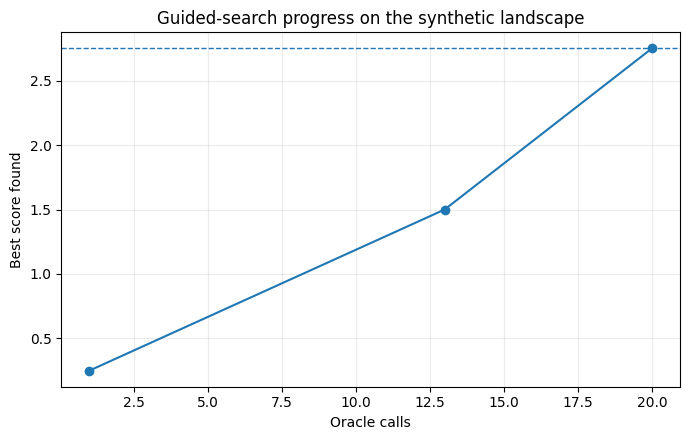

In [5]:
guided_example = guided_search(
    parent=parent,
    score_fn=dummy_score,
    budget=2,
    beam_width=3,
    max_oracle_calls=20,
    max_rounds=5,
    elementary_only=False,
    seed=42,
)

history = pd.DataFrame(guided_example["history"])
display(history)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(history["oracle_calls"], history["best_score"], marker="o")
ax.axhline(optimal_score, linestyle="--", linewidth=1)
ax.set_xlabel("Oracle calls")
ax.set_ylabel("Best score found")
ax.set_title("Guided-search progress on the synthetic landscape")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Reproducibility

All stochastic methods are evaluated over the same 100 integer seeds.
Candidate collections are deterministically ordered before random
sampling so that results are reproducible across Python sessions.

4. Repeated 100-seed benchmark

In [6]:
import statistics

N_SEEDS = 100

records = []

for seed in range(N_SEEDS):
    random_results = random_search(
        parent=parent,
        score_fn=dummy_score,
        budget=2,
        n_samples=19,
        elementary_only=False,
        seed=seed,
    )
    _, random_score = random_results[0]

    rank_results = generate_and_rank(
        parent=parent,
        score_fn=dummy_score,
        budget=2,
        n_candidates=19,
        seed=seed,
    )
    _, rank_score = rank_results[0]

    guided = guided_search(
        parent=parent,
        score_fn=dummy_score,
        budget=2,
        beam_width=3,
        max_oracle_calls=20,
        max_rounds=5,
        elementary_only=False,
        seed=seed,
    )
    guided_score = guided["best_score"]

    for method, score in [
        ("Random search", random_score),
        ("Generate-and-rank", rank_score),
        ("Guided search", guided_score),
    ]:
        records.append({
            "seed": seed,
            "method": method,
            "best_score": score,
            "regret": optimal_score - score,
            "found_optimum": abs(optimal_score - score) < 1e-12,
        })

toy_runs = pd.DataFrame(records)

toy_summary = (
    toy_runs.groupby("method", as_index=False)
    .agg(
        mean_best_score=("best_score", "mean"),
        mean_regret=("regret", "mean"),
        median_regret=("regret", "median"),
        regret_sd=("regret", "std"),
        optimum_recovery=("found_optimum", "mean"),
    )
)

toy_summary["optimum_recovery_pct"] = 100 * toy_summary["optimum_recovery"]
display(toy_summary)

,method,mean_best_score,mean_regret,median_regret,regret_sd,optimum_recovery,optimum_recovery_pct
0,Generate-and-rank,2.6550,0.0950,0.00,0.131905,0.64,64.0
1,Guided search,2.6775,0.0725,0.00,0.114012,0.71,71.0
2,Random search,2.5975,0.1525,0.25,0.166268,0.46,46.0


5. Optimum recovery

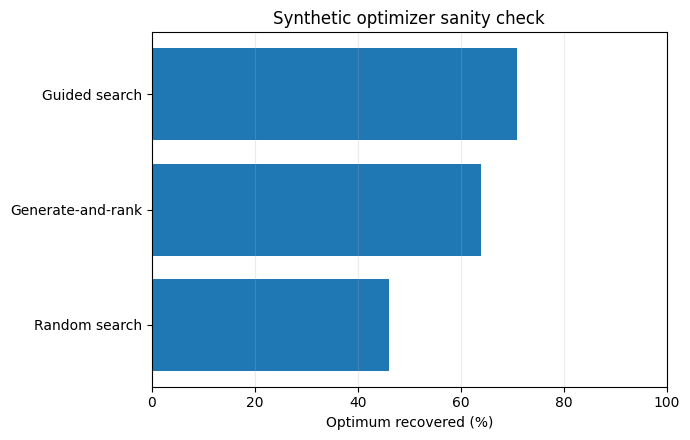

In [7]:
plot_df = toy_summary.sort_values("optimum_recovery_pct")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(plot_df["method"], plot_df["optimum_recovery_pct"])
ax.set_xlabel("Optimum recovered (%)")
ax.set_title("Synthetic optimizer sanity check")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

6. Mean regret

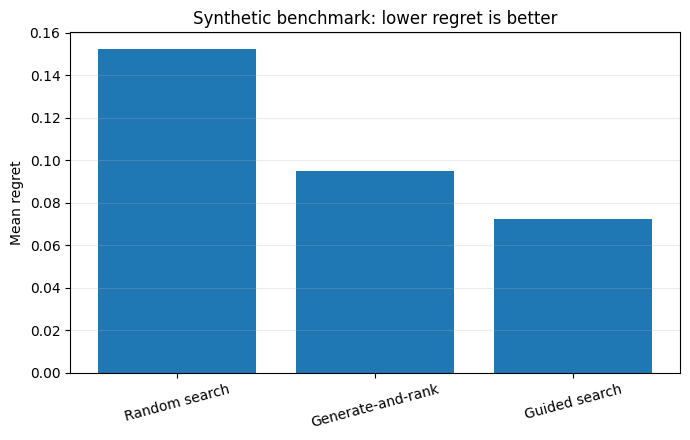

In [8]:
plot_df = toy_summary.sort_values("mean_regret", ascending=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(plot_df["method"], plot_df["mean_regret"])
ax.set_ylabel("Mean regret")
ax.set_title("Synthetic benchmark: lower regret is better")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

Takeaway
This benchmark validates the search infrastructure, not biological performance. The score is artificial and therefore should not be presented as evidence that one method is scientifically superior. The real retrospective PAMPA benchmark is presented in Notebook 05.